# EfficientNet_03: EfficientNet-B0, grouped split (34 species, unseen recordings), 3 seeds

**Change vs 02b: optimisation + regularisation only** (DL Lab 3: tune the learning rate first).
* lr 1e-3 → **1e-4** (1e-3 is high for fine-tuning a pretrained network)
* AdamW weight decay 1e-4 → **1e-2** (as in REPSOL)
* max epochs 10 → 15, patience 3 → 4 (a smaller lr needs more epochs)

Everything else is the 2025 recipe (see `EfficientNet_02.ipynb`). **Selection rule:** runs are compared on mean
*validation* macro-F1 over seeds 42/43/44; test metrics are recorded but not used for choosing.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
from src import config
import torch
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none")

GPU: NVIDIA GeForce RTX 5050 Laptop GPU


In [2]:
from src.EfficientNet.experiment import run_seeds
RUN = "EfficientNet_03"
df = run_seeds(RUN, split="grouped", augment=False, lr=1e-4, weight_decay=1e-2, max_epochs=15, patience=4)
df

device=cuda | classes=34 | train=9502 val=2102 test=2057


Epoch 1/15 | train loss 1.6153 acc 71.06 | val loss 3.0801 acc 40.72 | lr 1.00e-04 | 145s


  saved best checkpoint -> efficientnet_03_s42_best_01.pth


Epoch 2/15 | train loss 0.4244 acc 92.52 | val loss 3.2151 acc 39.20 | lr 1.00e-04 | 55s


Epoch 3/15 | train loss 0.1854 acc 96.24 | val loss 3.6317 acc 43.29 | lr 1.00e-04 | 55s


Epoch 4/15 | train loss 0.0890 acc 97.71 | val loss 4.0394 acc 45.05 | lr 1.00e-04 | 51s


... (23 outputs left out)

  early stopping (no val-loss improvement for 4 epochs)


Training finished.

--> EfficientNet_03_s44: val F1 0.306 acc 0.418 | best epoch 2/6


,run,seed,split,config,best_epoch,epochs_run,val_loss,val_acc,val_f1_macro,test_acc,test_f1_macro,minutes
0,EfficientNet_03,42,grouped,"{""augment"": false, ""lr"": 0.0001, ""weight_decay...",1,5,3.0801,0.4072,0.3021,0.5411,0.3987,8.9
1,EfficientNet_03,43,grouped,"{""augment"": false, ""lr"": 0.0001, ""weight_decay...",1,5,2.7217,0.3792,0.2797,0.5591,0.4051,4.6
2,EfficientNet_03,44,grouped,"{""augment"": false, ""lr"": 0.0001, ""weight_decay...",2,6,3.1802,0.4177,0.3056,0.6320,0.4652,5.6


In [3]:
df[["val_f1_macro", "val_acc", "test_f1_macro", "test_acc", "best_epoch"]].agg(["mean", "std"]).round(3)

,val_f1_macro,val_acc,test_f1_macro,test_acc,best_epoch
mean,0.296,0.401,0.423,0.577,1.333
std,0.014,0.020,0.037,0.048,0.577


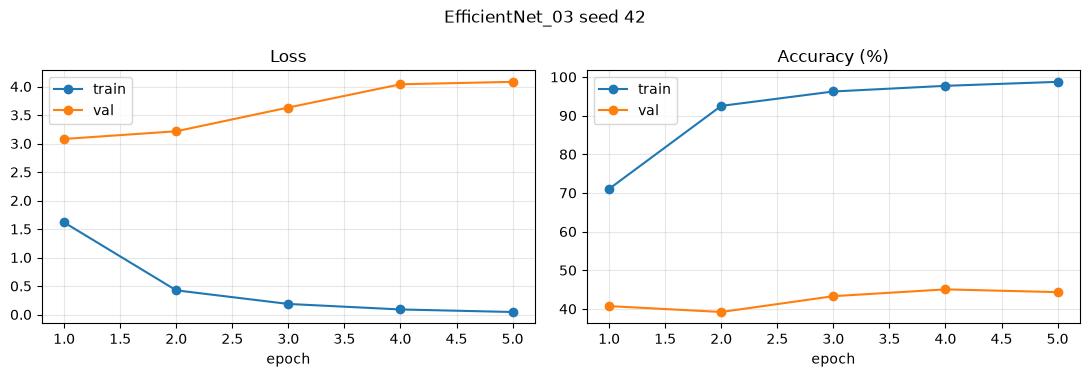

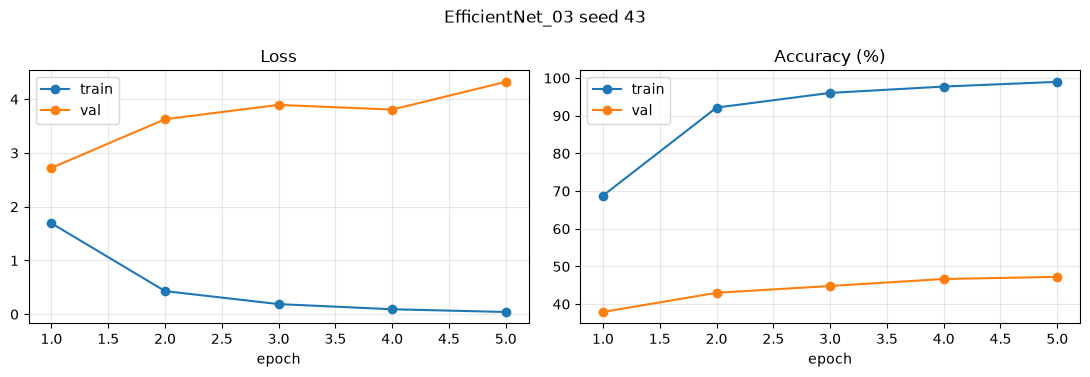

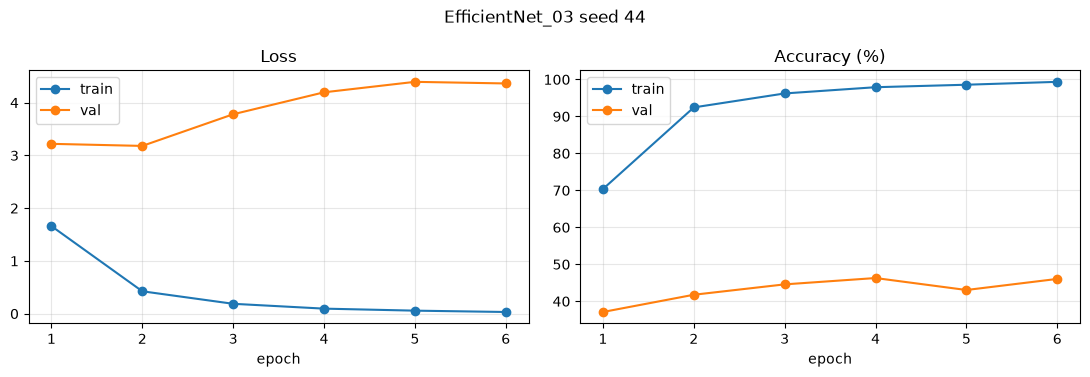

In [4]:
from src.plot_analysis import plot_learning_curves
import matplotlib.pyplot as plt
for s in df.seed:
    h = sorted(config.MODELS_OUTPUT.glob(f"{RUN.lower()}_s{s}_best_*_training_history.csv"))[-1]
    plot_learning_curves(h, f"{RUN} seed {s}", config.EVAL_DIR / f"learning_curves_{RUN}_s{s}.png"); plt.show()